# Guía práctica de GeoPandas con datos reales de pozos

Esta guía recorre, con los datos de este proyecto, las operaciones de GeoPandas que usan
`preprocess_areas.py` y `preprocess_geo.py`. Cada sección es una herramienta:

1. **GeoDataFrame**: una tabla de pandas con una columna de geometría y un CRS
2. **Leer capas**: `read_file`, problemas de encoding, filtrar por `bbox`
3. **Crear puntos** desde una tabla: `points_from_xy`
4. **CRS y proyecciones**: por qué no se mide en grados (`to_crs`)
5. **Spatial join**: en qué polígono cae cada punto (`sjoin`)
6. **Vecino más cercano**: distancias a líneas (`sjoin_nearest`)
7. **Overlay**: recortar líneas por polígonos y medir longitudes
8. **Dissolve**: unir polígonos por un atributo
9. **Exportar** liviano para la web: `simplify` + `to_file`

Requisitos: haber bajado los datos (ver README) y corrido los `preprocess_*.py`.

In [1]:
import os, json
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ftfy

# el notebook vive en docs/: trabajar desde la raíz del proyecto
if not os.path.exists("data"):
    os.chdir("..")

plt.rcParams.update({"figure.dpi": 80, "axes.grid": False})
print("geopandas", gpd.__version__)

geopandas 1.2.0


## 1-2. Leer una capa: el GeoDataFrame

`gpd.read_file` lee shapefiles, GeoJSON, GeoPackage, KML... (por debajo usa GDAL vía `pyogrio`).
El resultado es un **GeoDataFrame**: un DataFrame normal más una columna `geometry` y un **CRS**
(sistema de coordenadas).

In [2]:
cuencas = gpd.read_file("data/geo/cuencas/cuencas.shp")
print("CRS:", cuencas.crs)
print("Tipos de geometría:", cuencas.geom_type.value_counts().to_dict())
cuencas[["CUENCA", "TIPO", "UBICACION"]].head()

CRS: EPSG:4326
Tipos de geometría: {'Polygon': 22, 'MultiPolygon': 2}


,CUENCA,TIPO,UBICACION
0,CAÃADON ASFALTO,No Productiva,ONSHORE
1,MERCEDES,No Productiva,ONSHORE
2,BOLSONES INTERMONTANOS,No Productiva,ONSHORE
3,NORESTE,No Productiva,ONSHORE
4,PENINSULA VALDÃS,No Productiva,OFFSHORE


Fijate en los nombres: `CAÃ` + un carácter invisible en vez de `CAÑ`, y `VALDÃ` en vez de `VALDÉ`. Es **mojibake**: texto UTF-8 leído como si
fuera Latin-1. Es muy común en shapefiles argentinos (el `.dbf` no siempre declara bien su
encoding). `ftfy` lo repara; otra opción es probar `read_file(..., encoding="utf-8")` o `"cp1252"`.

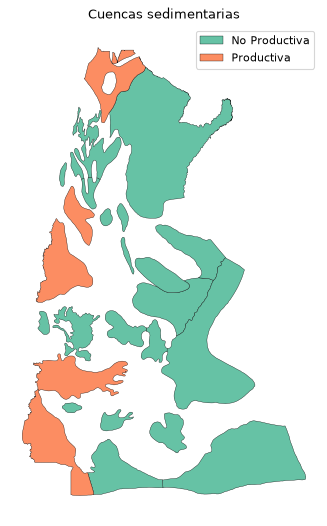

In [3]:
cuencas["CUENCA"] = cuencas["CUENCA"].map(ftfy.fix_text)
cuencas = cuencas.rename(columns={"CUENCA": "cuenca", "TIPO": "tipo"})
ax = cuencas.plot(column="tipo", cmap="Set2", edgecolor="k", linewidth=0.3, legend=True, figsize=(6, 8))
ax.set_title("Cuencas sedimentarias"); ax.set_axis_off()

## 3. Crear puntos desde una tabla: `points_from_xy`

Los pozos vienen como tabla con latitud y longitud. `points_from_xy(x, y)` arma las geometrías.
**Ojo con el orden: x = longitud, y = latitud.** Invertirlas es el error más común (en este
proyecto, el padrón oficial tenía pozos con lat/lon invertidas que caían en la Antártida).

In [4]:
txt = open("data/pozos_2025.js", encoding="utf-8").read()
rows = json.loads(txt[txt.index("=") + 1: txt.rindex(";")])
df = pd.DataFrame(rows, columns=["lat", "lon", "pet", "gas", "agua", "empresa", "cuenca_decl",
                                 "provincia", "tipo", "formacion", "meses", "estado", "sigla", "idpozo"])

pozos = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326")
print(len(pozos), "pozos con producción en 2025")
pozos[["idpozo", "sigla", "empresa", "cuenca_decl", "pet", "geometry"]].head(3)

27190 pozos con producción en 2025


,idpozo,sigla,empresa,cuenca_decl,pet,geometry
0,212,CH.CH.EaLE.x-1,COLHUE HUAPI S.A.,GOLFO SAN JORGE,738,POINT (-68.2879 -45.5911)
1,214,CH.CH.EaLE-3,COLHUE HUAPI S.A.,GOLFO SAN JORGE,943,POINT (-68.2839 -45.5902)
2,215,CH.CH.EaLE-4,COLHUE HUAPI S.A.,GOLFO SAN JORGE,651,POINT (-68.2895 -45.5941)


**Antes de cruzar nada: ¿cuál es la clave?** La sigla parece un identificador pero **no es única**:
hay pozos distintos con la misma sigla (ej. `T-22` es un pozo de El Trébol en Cuyana y otro de
Tecpetrol en el Noroeste). Si se agrupa o se hace `merge` por sigla, se suma la producción de pozos
distintos y se duplican ubicaciones (este proyecto inflaba así los totales un 5-7 %). La clave
correcta es `idpozo`.

In [5]:
print("pozos:", len(pozos), "| idpozo únicos:", pozos.idpozo.nunique(), "| siglas únicas:", pozos.sigla.nunique())
rep = pozos[pozos.sigla.duplicated(keep=False)].sort_values("sigla")
rep[["idpozo", "sigla", "empresa", "cuenca_decl", "lat", "lon"]].head(6)

pozos: 27190 | idpozo únicos: 27190 | siglas únicas: 25873


,idpozo,sigla,empresa,cuenca_decl,lat,lon
20579,157635,AEC.Nq.AC.a-2002,OILSTONE ENERGIA S.A.,NEUQUINA,-38.9691,-69.7234
20580,157636,AEC.Nq.AC.a-2002,OILSTONE ENERGIA S.A.,NEUQUINA,-38.9691,-69.7234
841,10035,AEC.RN.EV-24,PRESIDENT PETROLEUM S.A.,NEUQUINA,-38.6830,-67.2903
842,10036,AEC.RN.EV-24,PRESIDENT PETROLEUM S.A.,NEUQUINA,-38.6830,-67.2903
892,10204,AEC.RN.PP-14,PRESIDENT PETROLEUM S.A.,NEUQUINA,-38.5898,-67.4349
893,10205,AEC.RN.PP-14,PRESIDENT PETROLEUM S.A.,NEUQUINA,-38.5894,-67.4347


## 4. CRS: grados vs. metros

EPSG:4326 guarda **grados**. Un "área" o una "distancia" en grados no significa nada: un grado de
longitud mide ~111 km en el ecuador y ~70 km en Tierra del Fuego. Para medir hay que **proyectar**
(`to_crs`) a un CRS en metros.

Para todo el país usamos una Lambert azimutal equivalente centrada en Argentina. Para una zona
chica conviene la faja POSGAR que corresponda (ej. EPSG:5344 = POSGAR 2007 / Argentina 4).

In [6]:
METRIC = "+proj=laea +lat_0=-38 +lon_0=-65 +datum=WGS84 +units=m"

cuencas["area_grados"] = cuencas.area                      # sin sentido (GeoPandas avisa)
cuencas["km2"] = cuencas.to_crs(METRIC).area / 1e6         # correcto
cuencas[["cuenca", "area_grados", "km2"]].sort_values("km2", ascending=False).head()

,cuenca,area_grados,km2
3,NORESTE,61.954317,670949.297788
19,ARGENTINA,40.283843,359279.810188
5,MALVINAS ORIENTAL,40.020141,306487.813986
13,COLORADO MARINA,15.896316,149986.911094
15,NEUQUINA,15.064931,147152.800162


## 5. Spatial join: ¿en qué cuenca cae cada pozo?

`gpd.sjoin(puntos, poligonos, predicate="within")` es un *merge* donde la condición no es
"misma clave" sino una **relación espacial**. Cada pozo recibe las columnas del polígono que lo
contiene. Predicados útiles: `within`, `intersects`, `contains`, `touches`.

- `how="left"` conserva los pozos que no caen en ningún polígono (quedan con NaN).
- Si los polígonos se solapan, un punto aparece **dos veces**: revisar índices duplicados.
- Las dos capas tienen que estar en el **mismo CRS** (si no, GeoPandas avisa).

In [7]:
j = gpd.sjoin(pozos, cuencas[["cuenca", "geometry"]], predicate="within", how="left")
print("duplicados por solapamiento:", j.index.duplicated().sum())

resumen = j.groupby("cuenca").agg(pozos=("idpozo", "size"), petroleo_m3=("pet", "sum"),
                                  gas_mm3=("gas", "sum")).sort_values("petroleo_m3", ascending=False)
resumen.round(0)

duplicados por solapamiento: 0


,pozos,petroleo_m3,gas_mm3
cuenca,,,
NEUQUINA,11393,34354341,36999629
GOLFO SAN JORGE,14093,10612326,3535499
CUYANA,885,843731,37925
AUSTRAL MARINA,732,543537,6845519
NOROESTE,78,170210,1099824


**Control de calidad gratis:** la tabla trae la cuenca *declarada* por la empresa; el join da la
cuenca *geográfica*. Donde no coinciden hay un error de carga o un pozo en el borde de un
polígono (los límites de cuenca son aproximados).

In [8]:
alias = {"AUSTRAL": "AUSTRAL MARINA", "LOS BOLSONES": "BOLSONES INTERMONTANOS", "GENERAL LEVALLE": "LEVALLE"}
declarada = j["cuenca_decl"].replace(alias)
distintos = j[declarada != j["cuenca"]]
print(f"{len(distintos)} pozos con cuenca declarada distinta al polígono")
distintos[["idpozo", "sigla", "empresa", "cuenca_decl", "cuenca"]]

9 pozos con cuenca declarada distinta al polígono


,idpozo,sigla,empresa,cuenca_decl,cuenca
946,10464,TA.CMA-1.Car1.PH-1,TOTAL AUSTRAL S.A.,AUSTRAL,NaN
947,10465,TA.CMA-1.Car1.PH-3,TOTAL AUSTRAL S.A.,AUSTRAL,NaN
962,10931,TPT.St.CN.a-2,TECPETROL S.A.,NOROESTE,NaN
963,10934,TPT.St.CN.x-1,TECPETROL S.A.,NOROESTE,NaN
18686,153796,TAU.MA.Car.1-5(h).T1,TOTAL AUSTRAL S.A.,AUSTRAL,NaN
19074,154796,TAU.MA.Car.1-4(h),TOTAL AUSTRAL S.A.,AUSTRAL,NaN
23950,162738,PCR.LP.EM-2495,PETROQUIMICA COMODORO RIVADAVIA S.A.,NEUQUINA,NaN
23951,162739,PCR.LP.EM-2495,PETROQUIMICA COMODORO RIVADAVIA S.A.,NEUQUINA,NaN
24788,163789,CAP.Ch.F-289d,COMPAÑÍAS ASOCIADAS PETROLERAS S.A.,GOLFO SAN JORGE,NaN


## 6. Vecino más cercano: distancia al gasoducto troncal

`gpd.sjoin_nearest` busca, para cada pozo, la geometría más cercana de otra capa (puntos, líneas o
polígonos) y con `distance_col` devuelve la distancia. **Se calcula en las unidades del CRS**: por
eso primero se proyecta a metros.

Usa un índice espacial (STRtree): no compara cada pozo contra cada tramo, por eso es rápido aunque
sean 30 mil pozos contra cientos de líneas.

mediana: 25.4 km


Text(0, 0.5, 'pozos')

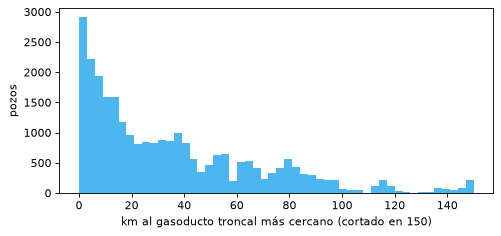

In [9]:
gasod = gpd.read_file("data/geo/gasoductos/gasoductos.shp", columns=["NOMBRE"])
cercano = gpd.sjoin_nearest(pozos.to_crs(METRIC), gasod.to_crs(METRIC), how="left", distance_col="dist_m")
cercano = cercano[~cercano.index.duplicated()]
pozos["dist_gasod_km"] = cercano["dist_m"] / 1000

print("mediana:", round(pozos.dist_gasod_km.median(), 1), "km")
ax = pozos.dist_gasod_km.clip(upper=150).plot.hist(bins=50, figsize=(7, 3), color="#4db6f0")
ax.set_xlabel("km al gasoducto troncal más cercano (cortado en 150)"); ax.set_ylabel("pozos")

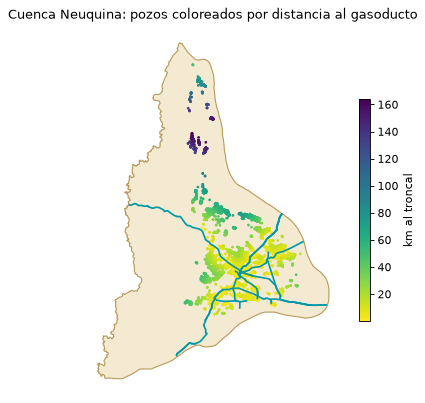

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
neuq = cuencas[cuencas.cuenca == "NEUQUINA"]
neuq.plot(ax=ax, color="#f4ead2", edgecolor="#b59a5a")
gasod.clip(neuq).plot(ax=ax, color="#0097a7", linewidth=1.5)       # clip: recortar al polígono
pozos.clip(neuq).plot(ax=ax, column="dist_gasod_km", cmap="viridis_r", markersize=2,
                      legend=True, legend_kwds={"label": "km al troncal", "shrink": 0.6})
ax.set_title("Cuenca Neuquina: pozos coloreados por distancia al gasoducto"); ax.set_axis_off()

## 7. Overlay: km de ductos dentro de cada concesión

Los ductos de yacimiento (Res. 319/93) son 179 mil tramos. Dos trucos:

- **Leer solo una zona** con `read_file(..., bbox=...)`: GDAL filtra al leer, sin cargar todo el país.
- **Deduplicar por geometría**: hay tramos cargados dos veces. `normalize()` ordena los vértices para
  que el mismo trazado compare igual aunque esté dibujado al revés.

Después `gpd.overlay(lineas, poligonos, how="intersection")` corta cada ducto en los límites de
cada concesión, y `.length` (en metros) da cuánto ducto hay en cada una.

In [11]:
bbox = tuple(neuq.total_bounds)                     # (xmin, ymin, xmax, ymax) de la Neuquina
duc = gpd.read_file("data/geo/ductos319/ductos319.shp", bbox=bbox, columns=["TIPO"])
print(len(duc), "tramos leídos en la caja de la Neuquina")
duc = duc[~duc.geometry.normalize().to_wkb().duplicated()]
print(len(duc), "sin duplicados")

areas = gpd.read_file("data/areas.geojson")[["nombre", "operador", "geometry"]]
inter = gpd.overlay(duc.to_crs(METRIC), areas.to_crs(METRIC), how="intersection", keep_geom_type=True)
inter["km"] = inter.length / 1000
inter.pivot_table(index="nombre", columns="TIPO", values="km", aggfunc="sum").fillna(0) \
     .sort_values("OLEODUCTO", ascending=False).head(8).round(0)

34467 tramos leídos en la caja de la Neuquina


31962 sin duplicados


TIPO,ACUEDUCTO,GASODUCTO,OLEODUCTO,OTROS,POLIDUCTO
nombre,,,,,
LOMA CAMPANA,618.0,1549.0,2668.0,0.0,0.0
EL TRAPIAL ESTE,494.0,85.0,967.0,0.0,0.0
EL TRAPIAL - CURAMCHED,494.0,99.0,967.0,0.0,0.0
AL NORTE DE LA DORSAL,108.0,395.0,937.0,2.0,0.0
PUESTO HERNANDEZ,639.0,251.0,925.0,0.0,0.0
CHIHUIDO DE LA SIERRA NEGRA,788.0,1586.0,880.0,0.0,0.0
VALLE DEL RIO GRANDE,63.0,307.0,857.0,0.0,0.0
JAGÜEL CASA DE PIEDRA,560.0,393.0,709.0,0.0,0.0


## 8. Dissolve: superficie concesionada por operador

`dissolve(by=...)` es un `groupby` que además **une las geometrías** de cada grupo. Sirve para pasar
de concesiones a "todo lo que opera YPF" como un único polígono.

In [12]:
por_op = areas.to_crs(METRIC).dissolve(by="operador", aggfunc={"nombre": "count"})
por_op["km2"] = por_op.area / 1e6
por_op = por_op.rename(columns={"nombre": "concesiones"}).sort_values("km2", ascending=False)
por_op[["concesiones", "km2"]].head(8).round(0)

,concesiones,km2
operador,,
VENOIL S.A.,10,10803.0
YPF S.A.,36,10783.0
COMPAÑÍA GENERAL DE COMBUSTIBLES S.A.,36,8102.0
TOTAL AUSTRAL S.A.,9,7542.0
PAN AMERICAN ENERGY SL,13,6512.0
ROCH S.A.,9,5068.0
TECPETROL S.A.,10,4296.0
PETROLEOS SUDAMERICANOS S.A.,15,4038.0


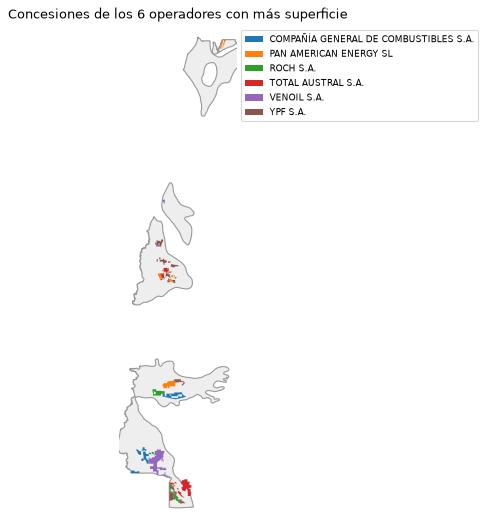

In [13]:
top = por_op.head(6).to_crs(4326).reset_index()
fig, ax = plt.subplots(figsize=(9, 8))
cuencas[cuencas.tipo == "Productiva"].plot(ax=ax, color="#eeeeee", edgecolor="#999999")
top.plot(ax=ax, column="operador", cmap="tab10", legend=True,
         legend_kwds={"loc": "upper left", "bbox_to_anchor": (1.0, 1.0), "fontsize": 8})
xmin, ymin, xmax, ymax = top.total_bounds          # encuadrar en las concesiones
ax.set_xlim(xmin - 1, xmax + 1); ax.set_ylim(ymin - 1, ymax + 1)
ax.set_title("Concesiones de los 6 operadores con más superficie"); ax.set_axis_off()

## 9. Exportar liviano para la web

Un visor web no necesita la precisión de un shapefile catastral. `simplify(tolerancia)` saca
vértices (tolerancia en unidades del CRS: acá grados, 0.003° ≈ 300 m) y `COORDINATE_PRECISION`
recorta decimales al escribir. Si una línea viene partida en miles de segmentos de 2 puntos,
`line_merge()` primero las une; si no, `simplify` no tiene nada que sacar.

In [14]:
os.makedirs("data/tmp", exist_ok=True)
gasod.to_file("data/tmp/gasod_full.geojson", driver="GeoJSON")
liviano = gasod.copy()
liviano["geometry"] = liviano.geometry.line_merge().simplify(0.003, preserve_topology=True)
liviano.to_file("data/tmp/gasod_web.geojson", driver="GeoJSON", COORDINATE_PRECISION=5)
for f in ["gasod_full", "gasod_web"]:
    print(f, round(os.path.getsize(f"data/tmp/{f}.geojson") / 1e6, 2), "MB")

gasod_full 30.13 MB
gasod_web 0.13 MB


## Errores comunes (y cómo se ven)

| Síntoma | Causa | Arreglo |
|---|---|---|
| Puntos en el océano o en la Antártida | lat/lon invertidas | `points_from_xy(lon, lat)` |
| Áreas como `0.0003` o distancias como `0.12` | CRS en grados | `to_crs` a un CRS métrico antes de medir |
| `UserWarning: CRS mismatch` en sjoin | capas en CRS distintos | `b = b.to_crs(a.crs)` |
| Más filas después del sjoin | polígonos solapados | `j[~j.index.duplicated()]` o agregar |
| Totales inflados después de un merge | la clave no es única (ej. sigla) | verificar `nunique()` y usar `idpozo` |
| `CAÃ‘ADON`, `PetrÃ³leo` | encoding del `.dbf` | `encoding=` en `read_file` o `ftfy` |
| GeoJSON enorme para la web | demasiados vértices/decimales | `line_merge`, `simplify`, `COORDINATE_PRECISION` |